# QPF ground-state preparation for the J1-J2 chain: full pipeline with gate costs

A standalone notebook (no project imports). It follows the filter of Stetcu, Baroni and Carlson (SBC) step by step:

1. **Parameters**
2. **Operators.** H and S² as sums of SWAPs, plus an ED reference that is used only to *measure* fidelity.
3. **Classical inputs from DMRG.** E0, Emax and the first excited singlet E1.
4. **Trial state.** The mps-to-circuit circuit for the DMRG ground state.
5. **J² projection.** The halving ladder π/4, π/8, ….
6. **Energy-filter design.** The authors' optimisation (Baroni's notebook): QPF(t,δ), QPF(t) and a constant schedule.
7. **Exact pipeline.** Ideal evolution, block iterated until 1−F ≤ ε.
8. **Trotterised circuits.** The controlled QPF step as a Qiskit circuit, a gate-exact simulator, and a check that they agree.
9. **Trotter step selection.** One step size per stage, set by the longest pulse.
10. **Resource estimate.** CNOTs, non-Clifford Rz, evolution time and Trotter steps per attempt and per success.

Requirements: `numpy scipy matplotlib quimb qiskit` and
`pip install --ignore-requires-python git+https://github.com/qiskit-community/mps-to-circuit`.
Ordering: qubit i = site i (Qiskit little-endian). The ancilla is qubit N.

## 1. Parameters

In [1]:
import time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
from scipy.optimize import minimize
import matplotlib.pyplot as plt

N = 10                 # spins (even); 8-12 run in minutes, 16 takes hours in step 9
J1, J2 = 1.0, 0.2411   # open J1-J2 chain
DELTA = 0.0            # dimerisation: J1 bonds are J1 (1 + DELTA (-1)^i). H still commutes with S^2
EPS = 1e-3             # target infidelity 1 - |<E0|psi>|^2
ORDER = 2              # Trotter order: 1 (Lie) or 2 (Suzuki)
LAYERS = 1             # mps-to-circuit layers for the trial
SEED = 0
M_RANGE = range(4, 13) # number of filter steps tried in the design
R_MAX = 6              # max energy-filter blocks

## 2. Operators
S_i·S_j = (2 SWAP_ij − 1)/4 and S² = Σ_{i<j} SWAP_ij + 3N/4 − N(N−1)/4. ED is used only as the reference for fidelity.

In [2]:
def bonds(N):
    return ([(i, i + 1, J1 * (1 + DELTA * (-1) ** i)) for i in range(N - 1)]
            + [(i, i + 2, J2) for i in range(N - 2)])

def swap_perm(N, i, j):
    s = np.arange(1 << N)
    flip = ((s >> i) & 1) != ((s >> j) & 1)
    return np.where(flip, s ^ (1 << i) ^ (1 << j), s)

def swap_sum(N, pairs, weights):
    d = 1 << N
    rows = np.concatenate([swap_perm(N, i, j) for i, j in pairs])
    cols = np.tile(np.arange(d), len(pairs))
    vals = np.concatenate([np.full(d, w, float) for w in weights])
    return sp.csr_matrix((vals, (rows, cols)), shape=(d, d))

B = bonds(N)
H = (swap_sum(N, [(i, j) for i, j, _ in B], [J / 2 for *_, J in B])
     - 0.25 * sum(J for *_, J in B) * sp.identity(1 << N)).tocsr()
PAIRS = [(i, j) for i in range(N) for j in range(i + 1, N)]
S2 = (swap_sum(N, PAIRS, np.ones(len(PAIRS))) + (0.75 * N - 0.25 * N * (N - 1)) * sp.identity(1 << N)).tocsr()
print("||[H, S^2]|| =", sp.linalg.norm(H @ S2 - S2 @ H))

# ED reference (fidelity only)
w, V = eigsh(H, k=1, which="SA", tol=1e-12)
E0_ex, g0 = w[0], V[:, 0]
Emax_ex = eigsh(H, k=1, which="LA", return_eigenvectors=False)[0]
ws = np.sort(eigsh(H + (Emax_ex - E0_ex) * S2, k=2, which="SA", return_eigenvectors=False))
print(f"ED: E0 = {E0_ex:.8f}, Emax = {Emax_ex:.6f}, first excited singlet = {ws[1]:.6f}")

||[H, S^2]|| = 6.106036759116657e-14
ED: E0 = -3.93612819, Emax = 2.732200, first excited singlet = -3.290645


## 3. Classical inputs from DMRG
E0 comes from H and Emax from −H. E1 is the first excited **singlet**: the lowest level of H + λS² + 2λ|ψ0⟩⟨ψ0|, with λ = Emax − E0. The J² penalty lifts every S > 0 state, and the projector lifts ψ0. After J² projection this is the gap the energy filter faces.

In [3]:
import quimb.tensor as qtn
import quimb.operator as qop

def heis_mpo(sign=1.0, s2=0.0):
    E = {}
    for i, j, J in B:
        E[(i, j)] = E.get((i, j), 0.0) + sign * J
    if s2:
        for i, j in PAIRS:
            E[(i, j)] = E.get((i, j), 0.0) + 2 * s2      # s2 (S^2 - 3N/4) = s2 sum_{i<j} 2 S_i.S_j
    return qop.heisenberg_from_edges(list(E), j=lambda i, j: E[(i, j)] if (i, j) in E else E[(j, i)]).build_mpo()

def seeded_mps(D=8):
    rng = np.random.default_rng(SEED)
    arrs = [rng.normal(size=(D, 2))] + [rng.normal(size=(D, D, 2)) for _ in range(N - 2)] + [rng.normal(size=(D, 2))]
    p = qtn.MatrixProductState(arrs, shape="lrp")
    return p / p.norm()

def dmrg(mpo):
    d = qtn.DMRG2(mpo, bond_dims=[16, 32, 64, 128], cutoffs=1e-12, p0=seeded_mps())
    np.random.seed(SEED)
    d.solve(tol=1e-10, verbosity=0, max_sweeps=40)
    return float(np.real(d.energy)), d.state

def projector_mpo(psi, max_bond=16):
    p = psi.copy(); p.compress(max_bond=max_bond); p /= p.norm(); p.permute_arrays("lrp")
    arrs = []
    for k, A in enumerate(p.arrays):
        if k in (0, N - 1):
            arrs.append(np.einsum("ru,sd->rsud", A, A.conj()).reshape(A.shape[0] ** 2, 2, 2))
        else:
            arrs.append(np.einsum("lru,msd->lmrsud", A, A.conj()).reshape(A.shape[0] ** 2, A.shape[1] ** 2, 2, 2))
    return qtn.MatrixProductOperator(arrs, shape="lrud")

E0, psi0 = dmrg(heis_mpo())
Emax = -dmrg(heis_mpo(sign=-1.0))[0]
lam = Emax - E0
E1 = dmrg(heis_mpo(s2=lam).add_MPO(projector_mpo(psi0) * (2 * lam)))[0] + lam * 0.75 * N
W = Emax - E0
gap = (E1 - E0) / W                                    # scaled singlet gap of H_s = (H - E0) / (Emax - E0)
print(f"DMRG: E0 = {E0:.8f} (ED {E0_ex:.8f}), Emax = {Emax:.6f}, E1 singlet = {E1:.6f} (ED {ws[1]:.6f})")
print(f"scaled singlet gap = {gap:.5f}")

DMRG: E0 = -3.93612819 (ED -3.93612819), Emax = 2.732200, E1 singlet = -3.290645 (ED -3.290645)
scaled singlet gap = 0.09680


## 4. Trial state: mps-to-circuit
The default approximate circuit for the DMRG ground state. γ = |⟨E0|trial⟩|² is measured against ED.

In [4]:
from mps_to_circuit import mps_to_circuit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

def counts(qc):
    """(CNOT, non-Clifford Rz) after transpiling at optimization level 3 to {cx, rz, sx, x}."""
    tq = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=3, seed_transpiler=0)
    rz = [float(g.operation.params[0]) for g in tq.data if g.operation.name == "rz"]
    nc = sum(abs(a / (np.pi / 2) - round(a / (np.pi / 2))) > 1e-9 for a in rz)
    return int(tq.count_ops().get("cx", 0)), int(nc)

m = psi0.copy(); m.permute_arrays("lrp")
trial_qc = mps_to_circuit(list(m.arrays), method="approximate", shape="lrp", num_layers=LAYERS)
psi = np.asarray(Statevector(trial_qc).data)
trial_cx, trial_rz = counts(trial_qc)
gamma = abs(np.vdot(g0, psi)) ** 2
pop = np.array([bin(i).count("1") for i in range(1 << N)])
print(f"trial: gamma = {gamma:.4f}, CNOT = {trial_cx}, non-Clifford Rz = {trial_rz}, "
      f"weight outside S^z = 0: {np.sum(abs(psi[pop != N // 2]) ** 2):.4f}")

trial: gamma = 0.8686, CNOT = 22, non-Clifford Rz = 46, weight outside S^z = 0: 0.0050


## 5. J² projection (exact)
All phases are zero. Step t keeps cos(t·S(S+1)), so t = π/4 zeroes S = 1, 2, 5, 6, … and halving the time picks up the sectors it missed. The success probability equals the trial's singlet weight.

In [5]:
def j2_ladder(Smax, t1=np.pi / 4):
    vals = np.array([S * (S + 1) for S in range(1, Smax + 1)], float)
    for n in range(1, 30):
        ts = [t1 / 2 ** k for k in range(n)]
        if np.all(abs(np.prod([np.cos(t * vals) for t in ts], axis=0)) < 1e-12):
            return ts

from scipy.sparse.linalg import expm_multiply

def qpf_step(O, v, t, d):
    """Exact post-selected step: cos(t O + d) v = (e^{-id} e^{-itO} + e^{id} e^{itO}) v / 2."""
    return 0.5 * (np.exp(-1j * d) * expm_multiply(-1j * t * O, v) + np.exp(1j * d) * expm_multiply(1j * t * O, v))

tJ = j2_ladder(N // 2)
v, pJ = psi.copy(), 1.0
for t in tJ:
    v = qpf_step(S2, v, t, 0.0); q = np.linalg.norm(v) ** 2; pJ *= q; v /= np.sqrt(q)
psiJ = v
print("J^2 times:", [f"{t:.4f}" for t in tJ])
print(f"success = {pJ:.4f}, gamma after = {abs(np.vdot(g0, psiJ)) ** 2:.4f}, <S^2> after = {np.vdot(psiJ, S2 @ psiJ).real:.2e}")

J^2 times: ['0.7854', '0.3927']
success = 0.9538, gamma after = 0.9107, <S^2> after = 5.17e-17


## 6. Energy-filter design (authors' notebook)
The pseudo-spectrum is [0, linspace(Δ, 1, 999)], with total time T = π/Δ, 0 ≤ t_i ≤ T/3 and |δ_i| ≤ π/2.
- **QPF(t,δ)** (v3) keeps Π cos²δ_i ≥ 0.9.
- **QPF(t)** (v4) has no phases.
- **Constant** uses m equal times.

m is chosen by lowest design cost, and the steps are run shortest first.

QPF (t,δ)  m =  6  T = 32.46  f(0)^2 = 0.900
QPF (t)    m =  6  T = 32.46  f(0)^2 = 1.000
Constant   m =  6  T = 32.46  f(0)^2 = 1.000
[101 s]


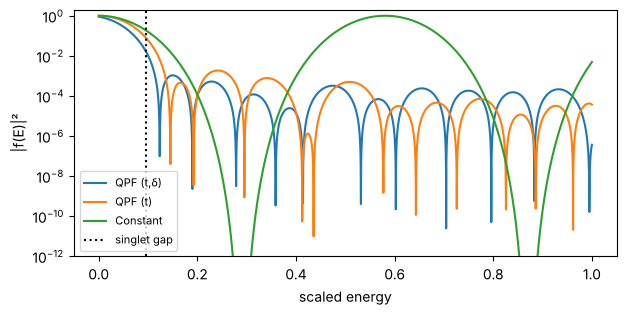

In [6]:
def design(gap, m, method):
    T = np.pi / gap
    E = np.concatenate([[0.0], np.linspace(gap, 1, 999)])
    cost = lambda t, d: abs(1 - np.prod(np.cos(d)) / np.sqrt(np.prod(np.cos(E[:, None] * t + d) ** 2, axis=1).sum()))
    fun = (lambda x: cost(x[:m], np.zeros(m))) if method == "v4" else (lambda x: cost(x[:m], x[m:]))
    cons = [{"type": "eq", "fun": lambda x: abs(np.sum(x[:m]) - T)}]
    if method == "v3":
        cons.append({"type": "ineq", "fun": lambda x: np.prod(np.cos(x[m:]) ** 2) - 0.9})
    h = 1 / 2 ** np.arange(m)
    r = minimize(fun, np.concatenate([T * h / h.sum(), np.zeros(m)]), method="SLSQP",
                 bounds=[(0, T / 3)] * m + [(-np.pi / 2, np.pi / 2)] * m, constraints=cons,
                 options=dict(maxiter=5000, ftol=1e-12), tol=1e-13)
    t, d = r.x[:m], (np.zeros(m) if method == "v4" else r.x[m:])
    return dict(times=t, phases=d, cost=float(r.fun), f0=float(np.prod(np.cos(d))))

def pick(gap, method):
    best = None
    for m in M_RANGE:
        q = design(gap, m, method)
        if method == "v3" and q["f0"] ** 2 < 0.85:          # infeasible SLSQP exit
            continue
        if best is None or q["cost"] < best["cost"] - 1e-9:
            best = dict(q, m=m)
    o = np.argsort(best["times"])
    best["times"], best["phases"] = best["times"][o], best["phases"][o]
    return best

t0 = time.time()
SCHED = {"QPF (t,δ)": pick(gap, "v3"), "QPF (t)": pick(gap, "v4")}
mc = SCHED["QPF (t)"]["m"]
SCHED["Constant"] = dict(times=np.full(mc, np.pi / gap / mc), phases=np.zeros(mc), m=mc)
for k, s in SCHED.items():
    print(f"{k:10s} m = {s['m']:2d}  T = {np.sum(s['times']):.2f}  f(0)^2 = {np.prod(np.cos(s['phases'])) ** 2:.3f}")
print(f"[{time.time() - t0:.0f} s]")

e = np.linspace(0, 1, 4000)
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, s in SCHED.items():
    ax.semilogy(e, np.prod(np.cos(np.outer(e, s["times"]) + s["phases"]), axis=1) ** 2 + 1e-18, label=k)
ax.axvline(gap, color="k", ls=":", label="singlet gap")
ax.set(xlabel="scaled energy", ylabel="|f(E)|²", ylim=(1e-12, 2)); ax.legend(fontsize=8); plt.show()

## 7. Exact pipeline (no Trotter)
The filter acts on H_s = (H − E0)/(Emax − E0) with the DMRG E0 and Emax. Each block of steps is repeated until 1−F ≤ ε.

In [7]:
Hs = ((H - E0 * sp.identity(1 << N)) / W).tocsr()
exact = {}
for k, s in SCHED.items():
    v, P, rows = psiJ.copy(), pJ, []
    for R in range(1, R_MAX + 1):
        for t, d in zip(s["times"], s["phases"]):
            v = qpf_step(Hs, v, t, d)
        q = np.linalg.norm(v) ** 2; P *= q; v /= np.sqrt(q)
        rows.append((R, P, 1 - abs(np.vdot(g0, v)) ** 2))
        if rows[-1][2] < EPS / 10:
            break
    exact[k] = rows
    print(k, "  ".join(f"R={R}: P={P:.3f} 1-F={f:.1e}" for R, P, f in rows))

QPF (t,δ) R=1: P=0.783 1-F=1.1e-03  R=2: P=0.704 1-F=1.9e-05
QPF (t) R=1: P=0.873 1-F=5.2e-03  R=2: P=0.869 1-F=3.9e-04  R=3: P=0.869 1-F=2.9e-05
Constant R=1: P=0.880 1-F=1.2e-02  R=2: P=0.871 1-F=2.3e-03  R=3: P=0.869 1-F=4.2e-04  R=4: P=0.869 1-F=9.1e-05


## 8. Trotterised circuits
The step exp(−i(tO+δ)⊗Y_a) = V·exp(−i(tO+δ)⊗Z_a)·V† uses V = S·H on the ancilla. With O = c + Σ w_k SWAP_k and SWAP = (I+XX+YY+ZZ)/2, the operator O⊗Z_a is a sum of XXZ, YYZ, ZZZ and Z_a terms. It is evolved with a `PauliEvolutionGate` (LieTrotter or SuzukiTrotter(order=2)).

The simulator applies the same product, one controlled SWAP at a time. On ancilla branch s = ±1, exp(−i s w dt SWAP) = cos(w dt) − i s sin(w dt) SWAP. Below it is checked against the transpiled circuit.

In [8]:
class SwapOp:
    """O = const + sum_k w_k SWAP_k."""
    def __init__(self, pairs, weights, const):
        self.pairs, self.w, self.c = pairs, np.asarray(weights, float), float(const)
        self.perms = [swap_perm(N, i, j) for i, j in pairs]

Hop = SwapOp([(i, j) for i, j, _ in B], [J / (2 * W) for *_, J in B], (-0.25 * sum(J for *_, J in B) - E0) / W)
Jop = SwapOp(PAIRS, np.ones(len(PAIRS)), 0.75 * N - 0.25 * N * (N - 1))

def step_circuit(op, t, d, n):
    terms = [("Z", [N], op.c + 0.5 * op.w.sum())]
    for (i, j), w in zip(op.pairs, op.w):
        terms += [(p * 2 + "Z", [i, j, N], w / 2) for p in "XYZ"]
    A = SparsePauliOp.from_sparse_list(terms, num_qubits=N + 1)
    qc = QuantumCircuit(N + 1)
    qc.sdg(N); qc.h(N)
    qc.append(PauliEvolutionGate(A, time=t, synthesis=LieTrotter(reps=n) if ORDER == 1 else SuzukiTrotter(order=2, reps=n)),
              range(N + 1))
    qc.rz(2 * d, N); qc.h(N); qc.s(N)
    return qc

def branch(op, V, t, n, s):
    dt = t / n
    seq = [(p, w * dt) for p, w in zip(op.perms, op.w)]
    if ORDER == 2:
        seq = [(p, a / 2) for p, a in seq]; seq = seq + seq[::-1]
    for _ in range(n):
        for p, a in seq:
            V = np.cos(a) * V - 1j * s * np.sin(a) * V[p]
    return np.exp(-1j * s * op.c * t) * V

def pulse(op, V, t, d, n):
    """Post-selected (ancilla 0) output of the Trotterised step, unnormalised."""
    return 0.5 * (np.exp(-1j * d) * branch(op, V, t, n, 1) + np.exp(1j * d) * branch(op, V, t, n, -1))

def run_transpiled(qc, tq, state):
    # statevector of the transpiled circuit with the output qubits relabelled back: level 3 may absorb SWAPs into a
    # final qubit permutation (tq.layout.final_layout), which is free (it only renames qubits)
    out = Statevector(state).evolve(tq).data
    fl = tq.layout.final_layout if tq.layout is not None else None
    if fl is None:
        return out
    s = np.arange(len(out)); src = np.zeros_like(s)
    for i, q in enumerate(qc.qubits):
        src |= ((s >> i) & 1) << fl[q]
    return out[src]

# check: transpiled circuit == simulator
s = SCHED["QPF (t,δ)"]
for op, t, d, n in ((Hop, s["times"][-1], s["phases"][-1], 2), (Jop, np.pi / 4, 0.0, 2)):
    qc = step_circuit(op, t, d, n)
    tq = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=3, seed_transpiler=0)
    out = run_transpiled(qc, tq, np.kron([1, 0], psi))[: 1 << N]
    print("max |circuit - simulator| =", np.max(abs(out - pulse(op, psi, t, d, n))))

max |circuit - simulator| = 1.4063068446439295e-14


max |circuit - simulator| = 3.4149513796221953e-14


## 9. Trotter step selection
There is one step size per stage, set by the longest pulse: dt = t_max / n_max. Pulse i gets n_i = round(t_i/dt) steps, and its time is snapped to n_i·dt.

We scan k (steps of the π/4 J² pulse), n_max (energy stage) and the number of blocks R, and keep the choice with the fewest CNOTs per success. A choice is valid only if 1−F ≤ ε holds at those steps **and** at the next finer k and the next finer n_max.

In [9]:
def uniform(times, nmax):
    dt = max(abs(np.asarray(times))) / nmax
    ns = [max(1, int(np.floor(abs(t) / dt + 0.5 + 1e-9))) for t in times]
    return ns, [np.sign(t) * n * dt for t, n in zip(times, ns)]

_cache = {}
def stage_counts(op, key, ts, ds, ns):
    out = np.zeros(2, int)
    for t, d, n in zip(ts, ds, ns):
        k = (key, round(t, 10), round(d, 10), n)
        if k not in _cache:
            _cache[k] = np.array(counts(step_circuit(op, t, d, n)))
        out += _cache[k]
    return out

def unique_grid(times, grid):
    seen, out = set(), []
    for g in grid:
        ns, ts = uniform(times, g)
        if tuple(ns) not in seen:
            seen.add(tuple(ns)); out.append((g, ns, ts))
    return out

K_GRID = unique_grid(tJ, [1, 2, 3, 4, 6, 8, 12, 16])
t0 = time.time()
J_out = []                                       # J^2 stage for every k: (k, ns, ts, normalised state, success, counts)
for k, ns, ts in K_GRID:
    v = psi.copy()
    for t, n in zip(ts, ns):
        v = pulse(Jop, v, t, 0.0, n)
    p = np.linalg.norm(v) ** 2
    J_out.append((k, ns, ts, v / np.sqrt(p), p, stage_counts(Jop, "J", ts, [0] * len(ts), ns)))
VJ = np.stack([x[3] for x in J_out], axis=1)

results = {}
for name, s in SCHED.items():
    grid = unique_grid(s["times"], [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24])
    inf = np.full((len(grid), len(K_GRID), R_MAX), np.inf); PP = np.zeros_like(inf)
    for gi, (g, ns, ts) in enumerate(grid):
        V, P = VJ.copy(), np.array([x[4] for x in J_out])
        for R in range(R_MAX):
            for t, d, n in zip(ts, s["phases"], ns):
                V = pulse(Hop, V, t, d, n)
            q = np.sum(abs(V) ** 2, axis=0); V /= np.sqrt(q); P = P * q
            inf[gi, :, R], PP[gi, :, R] = 1 - abs(g0.conj() @ V) ** 2, P
    best = None
    for gi in range(len(grid) - 1):
        for ki in range(len(K_GRID) - 1):
            for R in range(R_MAX):
                if max(inf[gi, ki, R], inf[gi + 1, ki, R], inf[gi, ki + 1, R]) > EPS:
                    continue
                cE = stage_counts(Hop, "H", grid[gi][2], s["phases"], grid[gi][1])
                cx, rz = np.array([trial_cx, trial_rz]) + J_out[ki][5] + (R + 1) * cE
                if best is None or cx / PP[gi, ki, R] < best["cx/success"]:
                    best = {"k (J^2 steps per pulse)": J_out[ki][1], "energy steps per pulse": grid[gi][1], "blocks": R + 1,
                            "1-F": inf[gi, ki, R], "success": PP[gi, ki, R], "CNOT/attempt": int(cx), "Rz/attempt": int(rz),
                            "cx/success": cx / PP[gi, ki, R], "Rz/success": rz / PP[gi, ki, R],
                            "time E (scaled)": (R + 1) * float(np.sum(np.abs(grid[gi][2]))),
                            "time J^2": float(np.sum(J_out[ki][2])),
                            "Trotter steps": int(sum(J_out[ki][1]) + (R + 1) * sum(grid[gi][1])),
                            "CNOT split (trial / J^2 / block)": (trial_cx, int(J_out[ki][5][0]), int(cE[0]))}
    results[name] = best
    print(f"{name}: done [{time.time() - t0:.0f} s]")

QPF (t,δ): done [14 s]


QPF (t): done [23 s]


Constant: done [34 s]


## 10. Resource estimate

In [10]:
print(f"N = {N}, eps = {EPS:g}, Trotter order {ORDER}, trial gamma = {gamma:.3f} ({LAYERS} layer(s)), "
      f"scaled singlet gap = {gap:.4f}, qubits = {N + 1}\n")
for name, r in results.items():
    print(f"--- {name}")
    if r is None:
        print("    target not reached on the grid"); continue
    for k, v in r.items():
        print(f"    {k:34s} {v:.4g}" if isinstance(v, float) else f"    {k:34s} {v}")

N = 10, eps = 0.001, Trotter order 2, trial gamma = 0.869 (1 layer(s)), scaled singlet gap = 0.0968, qubits = 11

--- QPF (t,δ)
    k (J^2 steps per pulse)            [3, 2]
    energy steps per pulse             [1, 1, 1, 1, 1, 2]
    blocks                             1
    1-F                                0.0005678
    success                            0.6991
    CNOT/attempt                       5806
    Rz/attempt                         2129
    cx/success                         8305
    Rz/success                         3046
    time E (scaled)                    37.86
    time J^2                           1.309
    Trotter steps                      12
    CNOT split (trial / J^2 / block)   (22, 3861, 1923)
--- QPF (t)
    k (J^2 steps per pulse)            [2, 1]
    energy steps per pulse             [1, 1, 1, 1, 2, 2]
    blocks                             2
    1-F                                0.0005382
    success                            0.6913
    CNOT/attempt

### Notes
- **CNOTs per success = CNOTs per attempt / success probability.** This assumes the whole circuit is rerun after a failed ancilla readout. Aborting at the first failure is cheaper, so these numbers are upper bounds.
- **Evolution time.** The energy-stage time is in units of H_s. The J² time is in units of S² (π/4 + π/8 + …).
- **ED.** The only ED inputs are g0 (for fidelity) and the reference energies printed in step 2. The pipeline itself uses only the DMRG numbers.